# O3 versus fixed 1× and ¼×

**Complete** · Comparison complete · ETA 0h 00m 00s

Seed 2026. O3 · 88-input Lasso 80,000/80,000, Fixed 1× 80,000/80,000, Fixed ¼× 80,000/80,000. Updated 2026-11-11T17:31:48+01:00.

## Reconstruction, health, forecast errors and compute

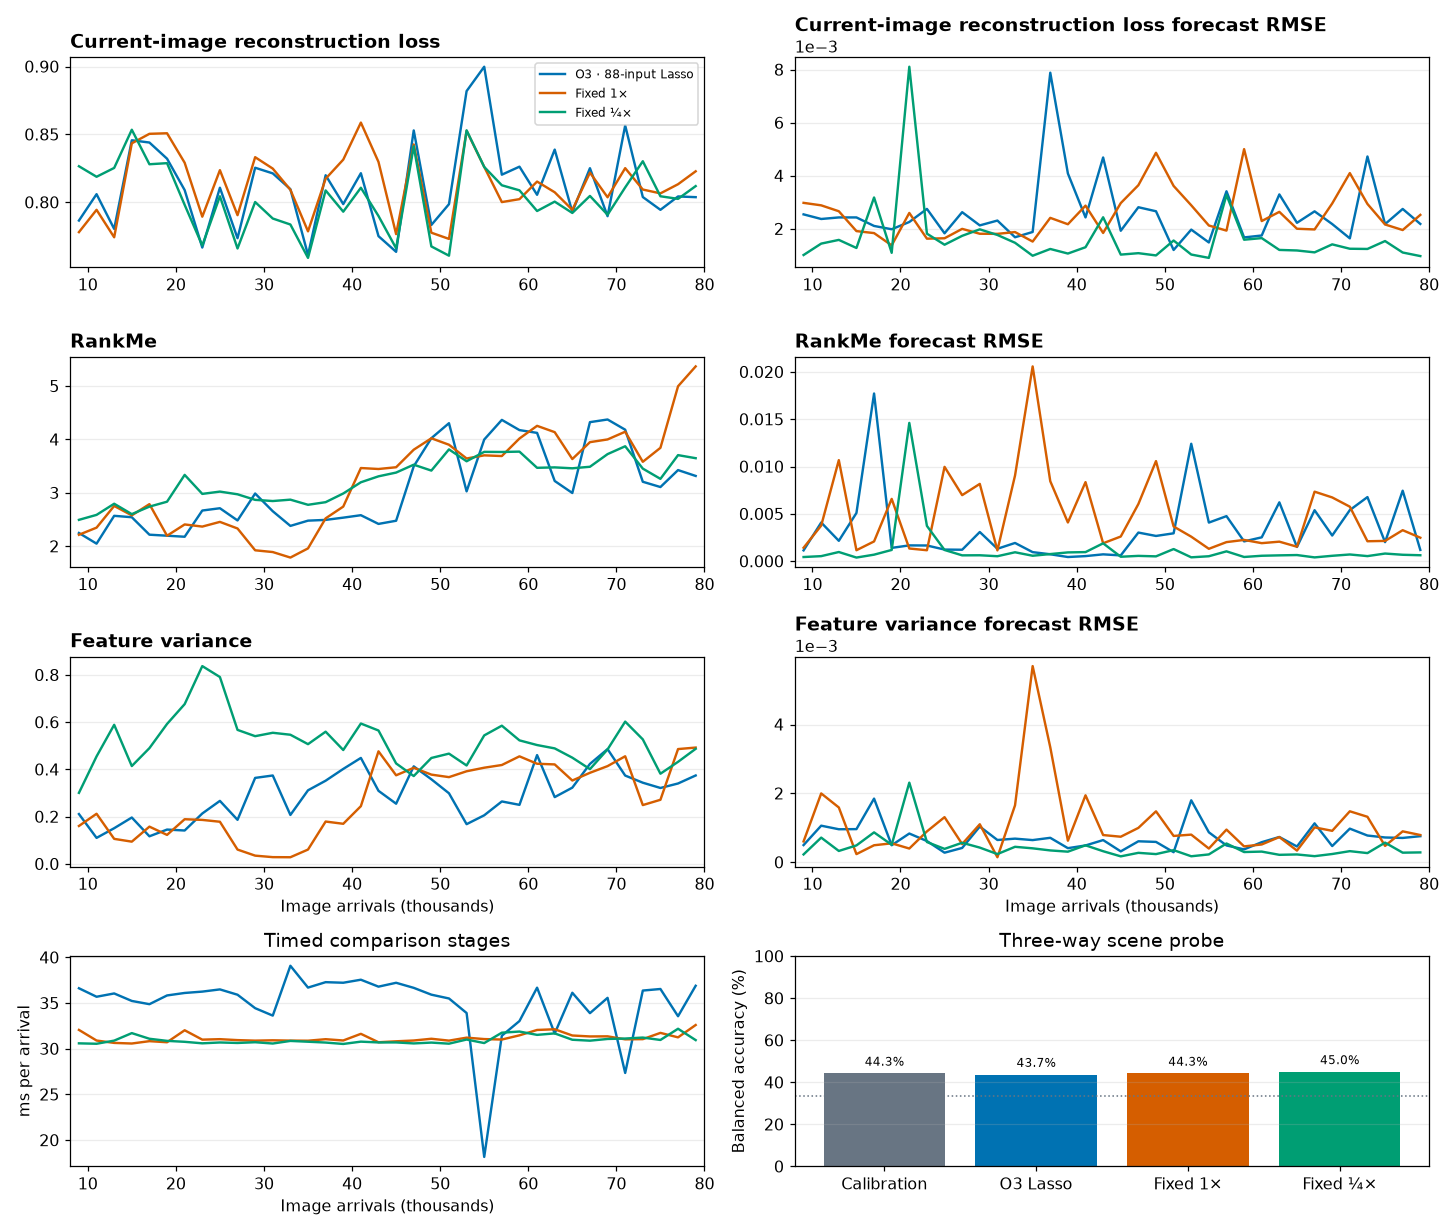

## Metrics pooled over saved arrivals

| Arm | Arrivals | Frame loss | RankMe | Variance | Loss RMSE | RankMe RMSE | Variance RMSE |
| --- | --- | --- | --- | --- | --- | --- | --- |
 | O3 · 88-input Lasso | 72000 | 0.811946 | 3.0715 | 0.29052 | 0.00289158 | 0.00474462 | 0.000790947 | 
 | Fixed 1× | 72000 | 0.813304 | 3.23278 | 0.273638 | 0.00265581 | 0.00628453 | 0.00146682 | 
 | Fixed ¼× | 72000 | 0.803602 | 3.24096 | 0.516968 | 0.00204513 | 0.00262973 | 0.000551951 | 

## Action shares and realized O3 improvement

| Arm | Skip | ¼× | 1× | Improved / arrivals | Improved / updates | Mean ΔO3 |
| --- | --- | --- | --- | --- | --- | --- |
 | O3 · 88-input Lasso | 7.65% | 15.87% | 76.48% | 91.01% | 98.54% | -0.02038 | 
 | Fixed 1× | 0.00% | 0.00% | 100.00% | 98.10% | 98.10% | -0.02223 | 
 | Fixed ¼× | 0.00% | 100.00% | 0.00% | 98.89% | 98.89% | -0.01598 | 

| O3 action | Executed | Improved | Improved / executed |
| --- | --- | --- | --- |
 | Skip | 5508 | 0 | 0.00% | 
 | ¼× | 11424 | 11065 | 96.86% | 
 | 1× | 55068 | 54459 | 98.89% | 

## Compute time

| Arm | Original 72k wall time | Comparison trace wall time | MAE ms / update | Predictor ms / arrival | Timed stages ms / arrival |
| --- | --- | --- | --- | --- | --- |
 | O3 · 88-input Lasso | 0h 43m 29s | 0h 43m 29s | 8.250 | 0.113 | 34.958 | 
 | Fixed 1× | 0h 20m 57s | 0h 39m 09s | 8.457 | 0.114 | 31.202 | 
 | Fixed ¼× | 0h 21m 05s | 0h 38m 46s | 8.437 | 0.145 | 30.958 | 

## Frozen-encoder linear probe

City street, highway and residential, with equal day/night counts inside each class. A fixed split uses 1,080 BDD100K validation keyframes for the logistic-regression fit and 540 disjoint keyframes for testing. Balanced-accuracy chance is 33.3%. Probe labels enter only the readout.

| Checkpoint | Scene balanced accuracy |
| --- | --- |
 | Shared calibration | 44.26% | 
 | O3 · 88-input Lasso | 43.70% | 
 | Fixed 1× | 44.26% | 
 | Fixed ¼× | 45.00% | 

## Protocol

All arms start from the same 8,000-arrival checkpoint and use the same image order. RankMe and variance use 128 bank images, replacing one oldest image after each 96th arrival. Positive means the observed scaled O3 objective fell after the executed action. Action shares include skips. Forecast RMSE covers executed updates and measures prediction error on each arm’s own trajectory.

The fixed arms reuse their original archived loss measurements. Replaying the exact updates supplies the 96-bank health and prequential Lasso shadow. The shadow learns from each fixed action after scoring. Original wall times include the diagnostics logged in each original run. The comparison-stage times include feature and shadow diagnostics for the fixed arms, with their archived loss measurements reused.

In [ ]:
# Run this cell to refresh the open notebook.
from IPython.display import clear_output, display, Image, Markdown
from pathlib import Path
import json, time

folder = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-fixed-comparison')
while True:
    try:
        status = json.loads((folder / 'status.json').read_text(encoding='utf-8'))
        chart = (folder / 'comparison.png').read_bytes()
    except (FileNotFoundError, PermissionError, ValueError):
        time.sleep(2)
        continue
    remaining = status['eta_seconds']
    eta = f'{remaining / 60:.1f} min' if remaining is not None else 'estimating'
    clear_output(wait=True)
    display(Markdown(f"**{status['state']}** · {status['stage']} · ETA {eta} · {status['cursors']}"))
    display(Image(data=chart))
    if status['state'] in ('complete', 'stopped', 'failed'):
        if status['error']:
            display(Markdown(status['error']))
        break
    time.sleep(10)
